# 08 - Panel 2011-2022: what happens when a commune's foreign share changes?

The 2022 cross-section compares communes **with each other**. Here the same 2,115 communes are followed over 12 years:
commune fixed effects remove everything about a commune that does not change, canton x year fixed effects remove
shocks that hit a whole canton in a given year. What is left is the change of the foreign share within a commune.

- **Input:** `data/processed/panel_2011_2022.csv` (from `code/02c_panel.py`), `data/processed/communes_2022.csv` (reference model M4)
- **Output:** `Results/panel/`

## 1. Setup

In [1]:
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf
sys.path.append("../code")
import helpers

OUT = helpers.results_dir("panel")
panel = pd.read_csv(helpers.PROCESSED / "panel_2011_2022.csv", encoding="utf-8-sig")

# Logs as in the cross-section: tax is very skewed; population and density span villages to Zurich
panel["log_population"] = np.log(panel["population"])
panel["log_density"] = np.log(panel["density"])
# Canton x year: the group for the canton-year fixed effects (e.g. "VD_2015")
panel["canton_year"] = panel["canton"] + "_" + panel["year"].astype(str)

YEARS = sorted(panel["year"].unique())
FIRST, LAST = YEARS[0], YEARS[-1]
print(f"{panel['code'].nunique():,} communes x {len(YEARS)} years ({FIRST}-{LAST}) = {len(panel):,} rows")

2,115 communes x 12 years (2011-2022) = 25,380 rows


## 2. How much did the foreign share change between 2011 and 2022?

Change in the foreign share, 2011 -> 2022 (percentage points)
              Communes  Mean  Median  10th pct  90th pct  Share that rose (%)
urban            509.0  3.39     3.3       0.3       6.7                91.94
intermediate     581.0  2.99     2.8      -0.2       6.5                88.30
rural           1001.0  2.88     2.6      -0.5       7.0                83.02
All communes    2091.0  3.03     2.8      -0.3       6.8                86.62


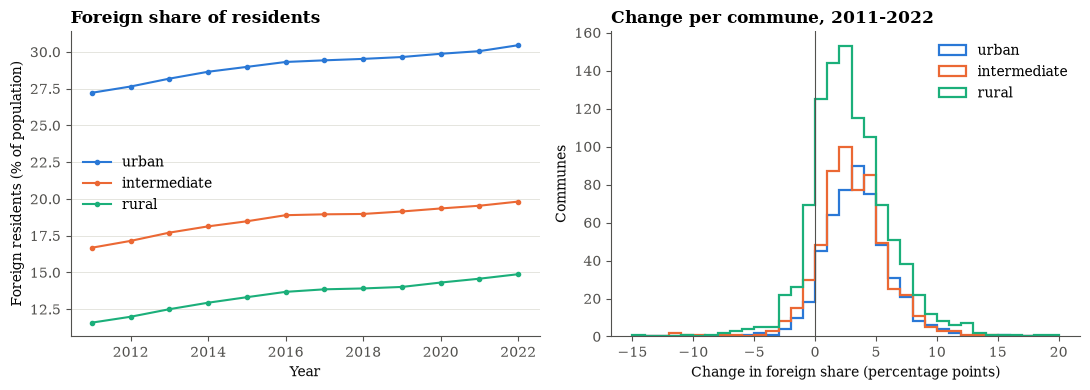

In [2]:
# How much did the foreign share change in each commune between the first and the last year?
wide = panel.pivot(index="code", columns="year", values="foreign_share")
change = pd.DataFrame({"change": wide[LAST] - wide[FIRST]}).join(
    panel[panel["year"] == LAST].set_index("code")[["name", "urban_rural", "population"]])

# Summary by urban/rural type (percentage points, 2011 -> 2022)
def describe_change(s):
    return pd.Series({"Communes": s.notna().sum(), "Mean": s.mean(), "Median": s.median(),
                      "10th pct": s.quantile(0.10), "90th pct": s.quantile(0.90),
                      "Share that rose (%)": 100 * (s > 0).mean()})

table_change = pd.concat(
    {**{t: describe_change(change.loc[change["urban_rural"] == t, "change"])
        for t in helpers.ORDER["urban_rural"]},
     "All communes": describe_change(change["change"])}, axis=1).T
table_change.to_csv(OUT / "table_change_foreign_share.csv")
print(f"Change in the foreign share, {FIRST} -> {LAST} (percentage points)")
print(table_change.round(2).to_string())

# Figure: left = foreign share over time by type (residents, not communes: foreigners / population),
#         right = distribution of the change per commune
trend = (panel.groupby(["year", "urban_rural"])[["foreigners", "population"]].sum()
              .assign(share=lambda d: 100 * d["foreigners"] / d["population"])["share"].unstack())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for t in helpers.ORDER["urban_rural"]:
    ax1.plot(trend.index, trend[t], marker="o", markersize=3, label=t,
             color=helpers.COLORS["urban_rural"][t])
ax1.set(title="Foreign share of residents", xlabel="Year", ylabel=helpers.LABELS["foreign_share"])
ax1.legend()
ax1.grid(axis="y")

bins = np.arange(-15, 20.5, 1)
for t in helpers.ORDER["urban_rural"]:
    ax2.hist(change.loc[change["urban_rural"] == t, "change"].clip(-15, 20), bins=bins,
             histtype="step", linewidth=1.6, label=t, color=helpers.COLORS["urban_rural"][t])
ax2.axvline(0, color=helpers.INK["secondary"], linewidth=0.8)
ax2.set(title=f"Change per commune, {FIRST}-{LAST}", xlabel="Change in foreign share (percentage points)",
        ylabel="Communes")
ax2.legend()
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_foreign_share_change.png")
plt.show()

## 3. Where is the variation? Between communes vs within communes

In [3]:
# Where is the variation? A fixed-effects model only uses what is left after removing
#   - the commune's own average over the years (commune fixed effects), and
#   - what all communes of a canton have in common in a given year (canton x year effects).
# The residual of a regression on fixed effects alone ("variable ~ 1 | fixed effects") is
# exactly that leftover. pyfixest does the fixed effects (fixef_rm="none": keep every row,
# so all columns of the table use the same observations).
def leftover(data, variable, fixed_effects):
    """What is left of `variable` after removing the fixed effects."""
    fit = pf.feols(f"{variable} ~ 1 | {fixed_effects}", data=data, fixef_rm="none")
    return pd.Series(fit.resid(), index=data.index)

variables = {"foreign_share": helpers.LABELS["foreign_share"],
             "log_tax": "Federal income tax per resident (log)",
             "sa_rate": helpers.LABELS["sa_rate"],
             "log_population": "Population (log)",
             "share_65plus": helpers.LABELS["share_65plus"],
             "jobs_per_capita": helpers.LABELS["jobs_per_capita"]}

rows = {}
for v, label in variables.items():
    d = panel[["code", "canton_year", v]].dropna()
    within = leftover(d, v, "code")                          # commune fixed effects only
    within_fe = leftover(d, v, "code + canton_year")         # + canton x year
    between = d[v] - within                                  # each commune's own average
    rows[label] = {"Total SD": d[v].std(),
                   "Between communes SD": between.std(),
                   "Within communes SD": within.std(),
                   "Within, after canton x year SD": within_fe.std(),
                   "Within share of variance (%)": 100 * within.var() / d[v].var(),
                   "Left for the panel model (%)": 100 * within_fe.var() / d[v].var()}
table_variation = pd.DataFrame(rows).T
table_variation.to_csv(OUT / "table_variation.csv")
print(table_variation.round(3).to_string())

                                       Total SD  Between communes SD  Within communes SD  Within, after canton x year SD  Within share of variance (%)  Left for the panel model (%)
Foreign residents (% of population)       9.686                9.555               1.588                           1.267                         2.689                         1.710
Federal income tax per resident (log)     0.698                0.674               0.181                           0.145                         6.720                         4.310
Social assistance rate (%)                1.629                1.548               0.509                           0.482                         9.745                         8.754
Population (log)                          1.239                1.238               0.051                           0.037                         0.172                         0.090
Residents aged 65+ (%)                    4.326                4.045               1.534       

## 4. Example communes: the largest rises and falls

                        name   urban_rural  population  share_2011  share_2022  change
code                                                                                  
5816  Corcelles-près-Payerne         urban        2844        16.3        31.3    15.0
749              Studen (BE)         urban        3463        12.6        26.5    13.9
2272         Misery-Courtion         rural        2321        17.8        29.8    12.0
102                   Weiach  intermediate        2077        13.8        25.3    11.5
2407               Oensingen         urban        6607        26.6        37.8    11.2
5407                  Leysin  intermediate        3719        61.7        51.4   -10.3
5072                   Faido         rural        2782        27.0        20.9    -6.1
5712                  Coppet         urban        3206        42.8        37.3    -5.5
1146                  Wauwil         rural        2558        27.7        22.7    -5.0
6253           Crans-Montana         urban 

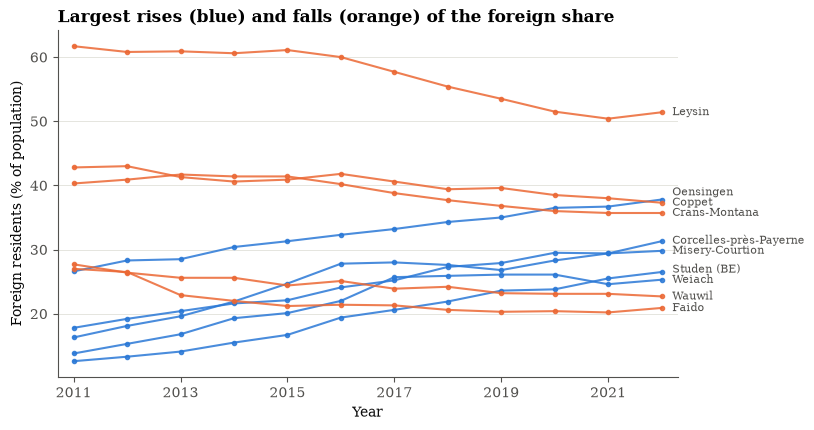

In [4]:
# Example communes: the largest rises and falls of the foreign share. Only communes with at
# least 2,000 residents, because in a village a few families moving already change the share a lot.
big = change[change["population"] >= 2000].dropna(subset=["change"])
examples = pd.concat([big.nlargest(5, "change"), big.nsmallest(5, "change")])
examples = examples.assign(**{f"share_{FIRST}": wide.loc[examples.index, FIRST],
                              f"share_{LAST}": wide.loc[examples.index, LAST]})
examples = examples[["name", "urban_rural", "population", f"share_{FIRST}", f"share_{LAST}", "change"]]
examples.to_csv(OUT / "table_example_communes.csv")
print(examples.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
for code, row in examples.iterrows():
    rising = row["change"] > 0
    ax.plot(YEARS, wide.loc[code, YEARS], marker="o", markersize=3,
            color=helpers.COLORS["urban_rural"]["urban" if rising else "intermediate"], alpha=0.85)

# Names at the end of each line; push labels apart when two lines end close together
ends = wide.loc[examples.index, LAST].sort_values()
label_y, previous = {}, -np.inf
for code, y in ends.items():
    label_y[code] = max(y, previous + 1.6)          # at least 1.6 points between two labels
    previous = label_y[code]
for code, y in label_y.items():
    ax.annotate(examples.loc[code, "name"], (LAST + 0.2, y), fontsize=8, va="center",
                color=helpers.INK["secondary"], annotation_clip=False)
ax.set_xticks(YEARS[::2])
ax.set(title="Largest rises (blue) and falls (orange) of the foreign share",
       xlabel="Year", ylabel=helpers.LABELS["foreign_share"], xlim=(FIRST - 0.3, LAST + 0.3))
ax.grid(axis="y")
helpers.save_figure(fig, OUT / "fig_example_communes.png")
plt.show()

## 5. Social assistance over the years: reported or hidden

In [5]:
# Social assistance over time: in how many years is each commune's rate reported?
# A commune can be hidden one year and visible the next (few recipients -> hidden).
reported = panel.assign(reported=panel["sa_rate"].notna()).pivot(index="code", columns="year", values="reported")
years_reported = reported.sum(axis=1)
switches = (reported.astype(int).diff(axis=1).abs().sum(axis=1) > 0)
table_sa_years = years_reported.value_counts().sort_index(ascending=False).rename("Communes").to_frame()
table_sa_years.index.name = "Years with SA reported"
table_sa_years.to_csv(OUT / "table_sa_years_reported.csv")
print(table_sa_years.T.to_string())
print(f"\nReported in all {len(YEARS)} years (balanced panel): {(years_reported == len(YEARS)).sum()} communes")
print(f"Never reported: {(years_reported == 0).sum()} | switch between hidden and reported: {switches.sum()}")

Years with SA reported    12  11  10  9   8   7   6   5   4   3   2   1    0 
Communes                1313  95  76  32  65  47  50  45  50  50  56  60  176

Reported in all 12 years (balanced panel): 1313 communes
Never reported: 176 | switch between hidden and reported: 626


## 6. Tables for the paper (description)

In [6]:
paper_tables = {"table_change_foreign_share": table_change,
                "table_variation": table_variation,
                "table_example_communes": examples}
for name, table in paper_tables.items():
    latex = table.to_latex(escape=True, na_rep="", float_format="%.2f")
    _ = (OUT / f"{name}.tex").write_text(latex, encoding="utf-8")
print("Saved:", len(paper_tables), "tables")

Saved: 3 tables


## 7. Fixed-effects regressions (pyfixest)

In [7]:
# Fixed-effects regressions with pyfixest. Formula: "outcome ~ regressors | fixed effects".
# Standard errors clustered by commune (CRV1): the errors of one commune are correlated
# from one year to the next. pyfixest drops "singletons" (a commune seen in only one year
# tells nothing about change), so the SA models have slightly fewer rows than the data.
warnings.filterwarnings("ignore", message=".*singleton fixed effect.*")

CONTROLS = ["log_population", "share_under20", "share_65plus", "jobs_per_capita"]
# No density: density = population / area and the area never changes, so with commune
# fixed effects log density = log population - constant -> the same variable twice.

SPECS = {
    "P1: commune + year FE": ("foreign_share", "code + year"),
    "P2: commune + canton x year FE": ("foreign_share", "code + canton_year"),
    "P3: P2 + controls": ("foreign_share + " + " + ".join(CONTROLS), "code + canton_year"),
}
OUTCOMES = {"log_tax": "Tax per resident (log)", "sa_rate": "SA rate (%)"}

def coef_row(outcome_label, model, b, se, p, n_obs, n_communes):
    return {"Outcome": outcome_label, "Model": model, "Foreign share": b, "SE": se,
            "p-value": p, "": helpers.stars(p), "Observations": n_obs, "Communes": n_communes}

fits, rows = {}, []
for outcome, outcome_label in OUTCOMES.items():
    for spec, (rhs, fixed_effects) in SPECS.items():
        fit = pf.feols(f"{outcome} ~ {rhs} | {fixed_effects}", data=panel, vcov={"CRV1": "code"})
        fits[(outcome, spec)] = fit
        rows.append(coef_row(outcome_label, spec, fit.coef()["foreign_share"], fit.se()["foreign_share"],
                             fit.pvalue()["foreign_share"], fit.sample_info.n_obs,
                             fit.fixef_counts.n_levels_by_fe[0]))     # first fixed effect = commune

# Reference: the 2022 cross-section (model M4 of notebook 04, canton FE, clustered by canton)
df, tax_sample, sa_sample = helpers.load_model_samples()
for outcome, sample in [("log_tax", tax_sample), ("sa_rate", sa_sample)]:
    m4 = helpers.fit_clustered(f"{outcome} ~ {helpers.M4_CONTROLS}", sample)
    rows.append(coef_row(OUTCOMES[outcome], "Cross-section 2022 (M4)", m4.params["foreign_share"],
                         m4.bse["foreign_share"], m4.pvalues["foreign_share"], len(sample), len(sample)))

table_fe = pd.DataFrame(rows).set_index(["Outcome", "Model"]).sort_index(level=0, sort_remaining=False)
print(table_fe.round(4).to_string())

# Full regression tables (every coefficient), one column per model
full = pf.etable(list(fits.values()), type="df", signif_code=[0.01, 0.05, 0.1])
_ = (OUT / "fixed_effects_full.md").write_text(full.to_markdown(), encoding="utf-8")

                                                       Foreign share      SE  p-value       Observations  Communes
Outcome                Model                                                                                      
SA rate (%)            P1: commune + year FE                  0.0030  0.0072   0.6798              19681      1878
                       P2: commune + canton x year FE         0.0188  0.0073   0.0098  ***         19680      1878
                       P3: P2 + controls                      0.0145  0.0074   0.0519    *         19680      1878
                       Cross-section 2022 (M4)                0.0515  0.0103   0.0000  ***          1625      1625
Tax per resident (log) P1: commune + year FE                 -0.0039  0.0016   0.0140   **         25223      2113
                       P2: commune + canton x year FE        -0.0050  0.0015   0.0008  ***         25223      2113
                       P3: P2 + controls                     -0.0032  0.0017   0

## 8. Long difference 2011-2022

In [8]:
# Long difference: one change per commune, 2011 -> 2022. Year-to-year changes of a small
# commune are mostly noise; over 11 years the real change is larger relative to the noise.
# Canton fixed effects here = each canton has its own trend.
def long_difference(outcome):
    cols = [outcome, "foreign_share"] + CONTROLS
    start = panel[panel["year"] == FIRST].set_index("code")[cols]
    end = panel[panel["year"] == LAST].set_index("code")
    diff = (end[cols] - start).add_prefix("d_").join(end[["canton", "population"]]).dropna()
    formula = f"d_{outcome} ~ d_foreign_share + " + " + ".join(f"d_{c}" for c in CONTROLS) + " + C(canton)"
    return helpers.fit_clustered(formula, diff), diff

ld_rows = []
for outcome, outcome_label in OUTCOMES.items():
    ld, diff = long_difference(outcome)
    _ = (OUT / f"long_difference_{outcome}.txt").write_text(ld.summary().as_text())
    ld_rows.append(coef_row(outcome_label, f"Long difference {FIRST}-{LAST}", ld.params["d_foreign_share"],
                            ld.bse["d_foreign_share"], ld.pvalues["d_foreign_share"], len(diff), len(diff)))
table_ld = pd.DataFrame(ld_rows).set_index(["Outcome", "Model"])
table_all = pd.concat([table_fe, table_ld]).sort_index(level=0, sort_remaining=False)
table_all.to_csv(OUT / "table_fixed_effects.csv")
print(table_all.round(4).to_string())

                                                       Foreign share      SE  p-value       Observations  Communes
Outcome                Model                                                                                      
SA rate (%)            P1: commune + year FE                  0.0030  0.0072   0.6798              19681      1878
                       P2: commune + canton x year FE         0.0188  0.0073   0.0098  ***         19680      1878
                       P3: P2 + controls                      0.0145  0.0074   0.0519    *         19680      1878
                       Cross-section 2022 (M4)                0.0515  0.0103   0.0000  ***          1625      1625
                       Long difference 2011-2022              0.0197  0.0113   0.0938    *          1445      1445
Tax per resident (log) P1: commune + year FE                 -0.0039  0.0016   0.0140   **         25223      2113
                       P2: commune + canton x year FE        -0.0050  0.0015   0

C:\Users\Owner\ADA\.venv\Lib\site-packages\statsmodels\base\model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 30, but rank is 5
  res = self.wald_test(
C:\Users\Owner\ADA\.venv\Lib\site-packages\statsmodels\base\model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 30, but rank is 5
  res = self.wald_test(


## 9. All estimates in one figure

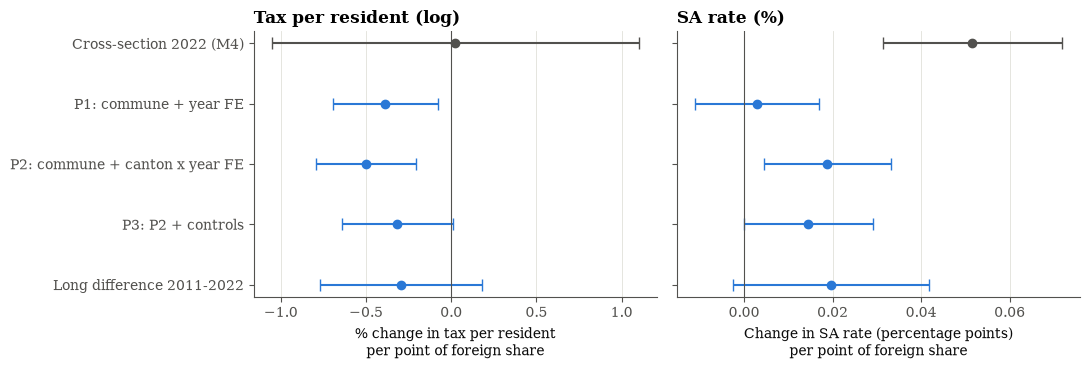

In [9]:
# One picture: the foreign-share coefficient in every model, with 95% confidence intervals.
# Tax: log coefficient x 100 = % change in tax per resident per point of foreign share.
# SA: percentage points of SA rate per point of foreign share.
order = ["Cross-section 2022 (M4)", *SPECS, f"Long difference {FIRST}-{LAST}"]
scale = {"Tax per resident (log)": 100, "SA rate (%)": 1}
xlabels = {"Tax per resident (log)": "% change in tax per resident\nper point of foreign share",
           "SA rate (%)": "Change in SA rate (percentage points)\nper point of foreign share"}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, outcome_label in zip(axes, OUTCOMES.values()):
    t = table_all.loc[outcome_label].loc[order]
    b, se = t["Foreign share"] * scale[outcome_label], t["SE"] * scale[outcome_label]
    y = np.arange(len(order))[::-1]
    colors = [helpers.INK["secondary"]] + [helpers.COLORS["urban_rural"]["urban"]] * (len(order) - 1)
    for yi, bi, si, c in zip(y, b, se, colors):
        ax.errorbar(bi, yi, xerr=1.96 * si, fmt="o", color=c, capsize=4)
    ax.axvline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_yticks(y, order)
    ax.set(title=outcome_label, xlabel=xlabels[outcome_label])
    ax.grid(axis="x")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_fixed_effects.png")
plt.show()

## 10. Tables for the paper (regressions)

In [10]:
latex = table_all.to_latex(escape=True, na_rep="", float_format="%.4f")
_ = (OUT / "table_fixed_effects.tex").write_text(latex, encoding="utf-8")
_ = (OUT / "fixed_effects_full.tex").write_text(pf.etable(list(fits.values()), type="tex", signif_code=[0.01, 0.05, 0.1]), encoding="utf-8")
print("Saved: table_fixed_effects.tex, fixed_effects_full.tex")

Saved: table_fixed_effects.tex, fixed_effects_full.tex


## 11. Robustness of the main panel model (P2)

In [11]:
# Robustness of the main panel model P2 (commune + canton x year fixed effects).
# P2, not P3, is the main model: when foreigners move in, the population and the age structure
# change BECAUSE of it, so controlling for them removes part of what we want to measure
# (bad controls; in the 2022 cross-section they were fixed characteristics, here they move).
size_2011 = panel.loc[panel["year"] == FIRST].set_index("code")["population"]
balanced_sa = years_reported[years_reported == len(YEARS)].index
panel["foreign_share_lag"] = panel.groupby("code")["foreign_share"].shift(1)   # previous year

def p2(outcome, data=panel, rhs="foreign_share", cluster="code", weights=None):
    """Model P2 with variations: other sample, regressor, clusters or weights."""
    return pf.feols(f"{outcome} ~ {rhs} | code + canton_year", data=data,
                    vcov={"CRV1": cluster}, weights=weights)

CHECKS = {
    "Main model (P2)": {},
    "Clustered by canton (26 clusters)": {"cluster": "canton"},
    "Weighted by population": {"weights": "population"},
    "Communes with 1,000+ residents in 2011": {"data": panel[panel["code"].map(size_2011) >= 1000]},
    "Without 2020-2021 (COVID)": {"data": panel[~panel["year"].isin([2020, 2021])]},
    "Previous year's foreign share": {"rhs": "foreign_share_lag"},
    "SA reported in all 12 years": {"data": panel[panel["code"].isin(balanced_sa)]},
}

rows = []
for outcome, outcome_label in OUTCOMES.items():
    for check, options in CHECKS.items():
        if check == "SA reported in all 12 years" and outcome != "sa_rate":
            continue                                      # tax is never hidden
        fit = p2(outcome, **options)
        x = options.get("rhs", "foreign_share")
        rows.append(coef_row(outcome_label, check, fit.coef()[x], fit.se()[x], fit.pvalue()[x],
                             fit.sample_info.n_obs, fit.fixef_counts.n_levels_by_fe[0]))
table_robust = pd.DataFrame(rows).set_index(["Outcome", "Model"])
table_robust.to_csv(OUT / "table_robustness.csv")
print(table_robust.round(4).to_string())

                                                               Foreign share      SE  p-value       Observations  Communes
Outcome                Model                                                                                              
Tax per resident (log) Main model (P2)                               -0.0050  0.0015   0.0008  ***         25223      2113
                       Clustered by canton (26 clusters)             -0.0050  0.0018   0.0103   **         25223      2113
                       Weighted by population                        -0.0086  0.0018   0.0000  ***         25223      2113
                       Communes with 1,000+ residents in 2011        -0.0068  0.0019   0.0003  ***         16320      1360
                       Without 2020-2021 (COVID)                     -0.0054  0.0016   0.0006  ***         21008      2111
                       Previous year's foreign share                 -0.0036  0.0015   0.0181   **         23113      2112
SA rate (%)     

## 12. Cities vs villages: one slope per commune type

In [12]:
# Cities vs villages. In the 2022 cross-section the tax slope was negative in urban and
# positive in rural communes. Does the same hold for CHANGES within communes?
# i(urban_rural, foreign_share) = one foreign-share slope per urban/rural type.
TYPES = helpers.ORDER["urban_rural"]
type_rows = []
for outcome, outcome_label in OUTCOMES.items():
    fit = p2(outcome, rhs="i(urban_rural, foreign_share)")
    names = [f"urban_rural::{t}:foreign_share" for t in TYPES]
    # Wald test: are the three slopes equal? (urban = intermediate and intermediate = rural)
    wald = fit.wald_test(R=np.array([[1, -1, 0], [0, 1, -1]]), q=np.zeros(2), distribution="chi2")
    # The same split in the 2022 cross-section (notebook 04)
    cross = helpers.fit_clustered(f"{outcome} ~ {helpers.M4_OTHER_CONTROLS} + C(urban_rural):foreign_share",
                                  sa_sample if outcome == "sa_rate" else tax_sample)
    for t, name in zip(TYPES, names):
        c = f"C(urban_rural)[{t}]:foreign_share"
        type_rows.append({"Outcome": outcome_label, "Type": t,
                          "Panel (P2)": fit.coef()[name], "Panel SE": fit.se()[name],
                          "Panel p": fit.pvalue()[name], "": helpers.stars(fit.pvalue()[name]),
                          "Cross-section 2022": cross.params[c], "Cross-section SE": cross.bse[c],
                          "Cross-section p": cross.pvalues[c], " ": helpers.stars(cross.pvalues[c]),
                          "Equal slopes, p (panel)": wald.pvalue})
table_types = pd.DataFrame(type_rows).set_index(["Outcome", "Type"])
table_types.to_csv(OUT / "table_slopes_by_type.csv")
print(table_types.round(4).to_string())

                                     Panel (P2)  Panel SE  Panel p       Cross-section 2022  Cross-section SE  Cross-section p       Equal slopes, p (panel)
Outcome                Type                                                                                                                                 
Tax per resident (log) urban            -0.0197    0.0021   0.0000  ***             -0.0153            0.0043           0.0014  ***                   0.0000
                       intermediate     -0.0106    0.0031   0.0007  ***             -0.0000            0.0057           0.9957                        0.0000
                       rural             0.0009    0.0018   0.6323                   0.0150            0.0059           0.0180   **                   0.0000
SA rate (%)            urban             0.0101    0.0131   0.4382                   0.0630            0.0096           0.0000  ***                   0.2231
                       intermediate      0.0338    0.0117 

## 13. Tax split: fewer filers, or lower tax per taxpayer?

In [13]:
# Why does tax per resident fall when a city's foreign share rises? Split it into three parts
# (as in notebook 04, section 5b); in logs the three slopes add up to the total:
#   log(tax / residents) = log(filers / residents) + log(taxpayers / filers) + log(tax / taxpayer)
# A falling "filers per resident" would point to newcomers who file no ordinary tax return
# (taxed at source, B and L permits): a MEASUREMENT effect, not lower incomes.
# A falling "tax per taxpayer" would point to lower incomes among those who do file.
panel["log_filers_per_resident"] = np.log(panel["filers"] / panel["population"])
panel["log_payers_per_filer"] = np.log(panel["taxpayers"] / panel["filers"])
panel["log_tax_per_payer"] = np.log(panel["tax_total"] / panel["taxpayers"])
PARTS = {"log_tax": "Total: tax per resident",
         "log_filers_per_resident": "Filers per resident",
         "log_payers_per_filer": "Taxpayers per filer",
         "log_tax_per_payer": "Tax per taxpayer"}

split_rows = []
for part, part_label in PARTS.items():
    fit = p2(part, rhs="i(urban_rural, foreign_share)")
    for t in TYPES:
        name = f"urban_rural::{t}:foreign_share"
        split_rows.append({"Part": part_label, "Type": t, "Foreign share": fit.coef()[name],
                           "SE": fit.se()[name], "p-value": fit.pvalue()[name],
                           "": helpers.stars(fit.pvalue()[name])})
table_split = pd.DataFrame(split_rows).set_index(["Type", "Part"]).sort_index(level=0, sort_remaining=False)
table_split.to_csv(OUT / "table_tax_split.csv")
print(table_split.round(4).to_string())

                                      Foreign share      SE  p-value     
Type         Part                                                        
intermediate Total: tax per resident        -0.0106  0.0031   0.0007  ***
             Filers per resident            -0.0053  0.0005   0.0000  ***
             Taxpayers per filer            -0.0019  0.0005   0.0000  ***
             Tax per taxpayer               -0.0034  0.0030   0.2610     
rural        Total: tax per resident         0.0009  0.0018   0.6323     
             Filers per resident            -0.0048  0.0004   0.0000  ***
             Taxpayers per filer             0.0012  0.0005   0.0107   **
             Tax per taxpayer                0.0045  0.0017   0.0091  ***
urban        Total: tax per resident        -0.0197  0.0021   0.0000  ***
             Filers per resident            -0.0072  0.0004   0.0000  ***
             Taxpayers per filer            -0.0041  0.0004   0.0000  ***
             Tax per taxpayer         

## 14. Figures: robustness and slopes by commune type

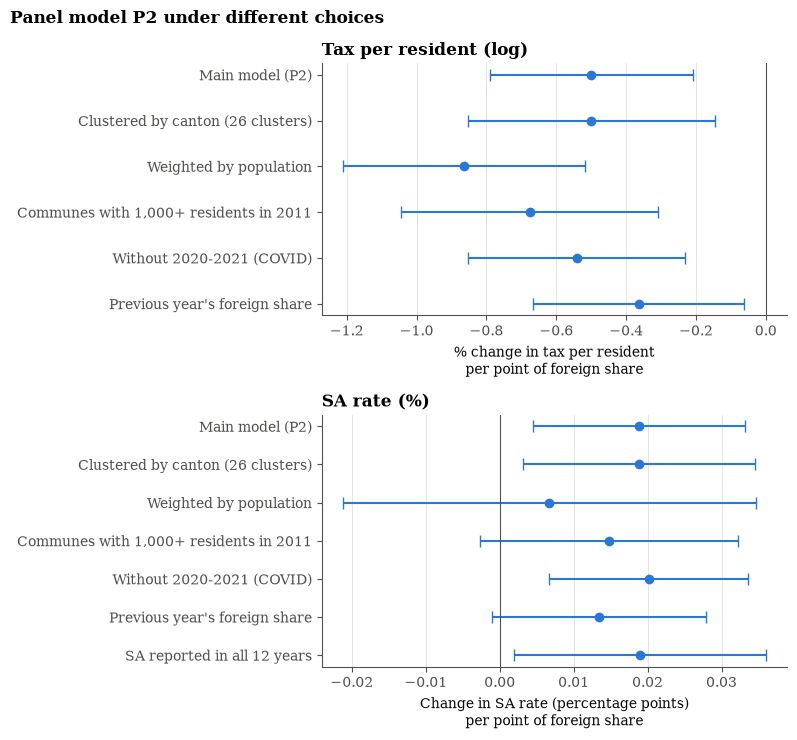

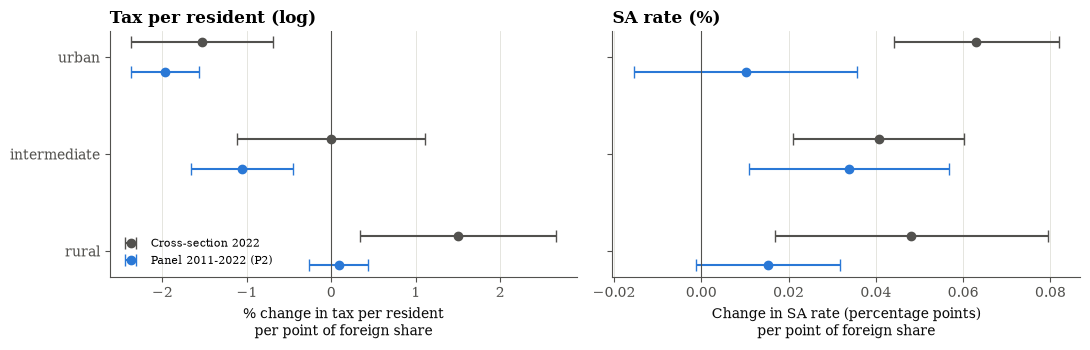

In [14]:
# Figures: (a) the main panel estimate under every robustness check,
#          (b) the slope by commune type, panel vs 2022 cross-section.
fig, axes = plt.subplots(2, 1, figsize=(8, 7.5))
for ax, outcome_label in zip(axes, OUTCOMES.values()):
    t = table_robust.loc[outcome_label]
    b, se = t["Foreign share"] * scale[outcome_label], t["SE"] * scale[outcome_label]
    y = np.arange(len(t))[::-1]
    ax.errorbar(b, y, xerr=1.96 * se, fmt="o", capsize=4, color=helpers.COLORS["urban_rural"]["urban"])
    ax.axvline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_yticks(y, t.index)
    ax.set(title=outcome_label, xlabel=xlabels[outcome_label])
    ax.grid(axis="x")
fig.suptitle("Panel model P2 under different choices", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_robustness.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, outcome_label in zip(axes, OUTCOMES.values()):
    t = table_types.loc[outcome_label]
    y = np.arange(len(TYPES))[::-1]
    for shift, col, se_col, color, label in [
            (0.15, "Cross-section 2022", "Cross-section SE", helpers.INK["secondary"], "Cross-section 2022"),
            (-0.15, "Panel (P2)", "Panel SE", helpers.COLORS["urban_rural"]["urban"], "Panel 2011-2022 (P2)")]:
        ax.errorbar(t[col] * scale[outcome_label], y + shift, xerr=1.96 * t[se_col] * scale[outcome_label],
                    fmt="o", capsize=4, color=color, label=label)
    ax.axvline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_yticks(y, TYPES)
    ax.set(title=outcome_label, xlabel=xlabels[outcome_label])
    ax.grid(axis="x")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_slopes_by_type.png")
plt.show()

## 15. Tables for the paper (robustness)

In [15]:
for name, table in {"table_robustness": table_robust, "table_slopes_by_type": table_types,
                    "table_tax_split": table_split}.items():
    latex = table.to_latex(escape=True, na_rep="", float_format="%.4f")
    _ = (OUT / f"{name}.tex").write_text(latex, encoding="utf-8")
print("Saved: table_robustness.tex, table_slopes_by_type.tex, table_tax_split.tex")

Saved: table_robustness.tex, table_slopes_by_type.tex, table_tax_split.tex
